# Confronto strutturale benchmark VMware vs Azure

Notebook a supporto paragrafo 6.3 ("Differenze strutturali nei benchmark Azure e VMware").

**Nota:** Questo confronto opera sui **dataset iniziali** (`cis_vmware.csv`, `cis_azure.csv`),
cioè sui valori C/D/R assegnati a ciascun controllo nella *definizione* del benchmark. Non opera quindi sui risultati
dell'audit eseguito sulle infrastrutture di test. È quindi un confronto tra la struttura dei due standard,
indipendente dalla dimensione e composizione delle infrastrutture usate in fase di sperimentazione.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

print('Setup completato.')

Setup completato.


## 2. Caricamento dei due dataset e calcolo di E_norm

Aggiornare i due path con la posizione dei due file csv.

In [2]:
VMWARE_CSV_PATH = '../cis_vmware.csv'   
AZURE_CSV_PATH  = '../cis_azure.csv'    

W_C, W_D, W_R = 0.40, 0.30, 0.30
assert abs(W_C + W_D + W_R - 1.0) < 1e-9, 'I pesi devono sommare a 1'


def load_and_compute_enorm(path, wc=W_C, wd=W_D, wr=W_R):
    """
    Carica il dataset e calcola E_i / E_norm con normalizzazione
    sui limiti teorici delle scale (coerente con module_scoring.ps1).
    """
    #df = pd.read_csv(path, encoding='utf-8-sig')
    try:
        df = pd.read_csv(path, encoding='cp1252', sep=None, engine='python')
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding='latin1', sep=None, engine='python')
    df.columns = df.columns.str.strip().str.lower()
    df = df.dropna(subset=['c', 'd', 'r']).copy()
    df[['c', 'd', 'r']] = df[['c', 'd', 'r']].astype(int)

    e_min = wc * 1 + wd * 0 + wr * 1
    e_max = wc * 3 + wd * 2 + wr * 3

    df['E_i'] = wc * df['c'] + wd * df['d'] + wr * df['r']
    df['E_norm'] = (df['E_i'] - e_min) / (e_max - e_min)
    return df


df_vmware = load_and_compute_enorm(VMWARE_CSV_PATH)
df_azure  = load_and_compute_enorm(AZURE_CSV_PATH)

print(f'VMware: {len(df_vmware)} controlli')
print(f'Azure : {len(df_azure)} controlli')

VMware: 39 controlli
Azure : 60 controlli


## 3. Statistiche descrittive di E_norm per piattaforma

In [3]:
summary = pd.DataFrame({
    'VMware': df_vmware['E_norm'].describe(),
    'Azure':  df_azure['E_norm'].describe(),
}).round(4)

display(summary)

,VMware,Azure
count,39.0000,60.0000
mean,0.1308,0.1700
std,0.2341,0.2432
min,0.0000,0.0000
25%,0.0000,0.0000
50%,0.0000,0.0000
75%,0.2500,0.3500
max,1.0000,1.0000


## 4. Box plot + istogramma

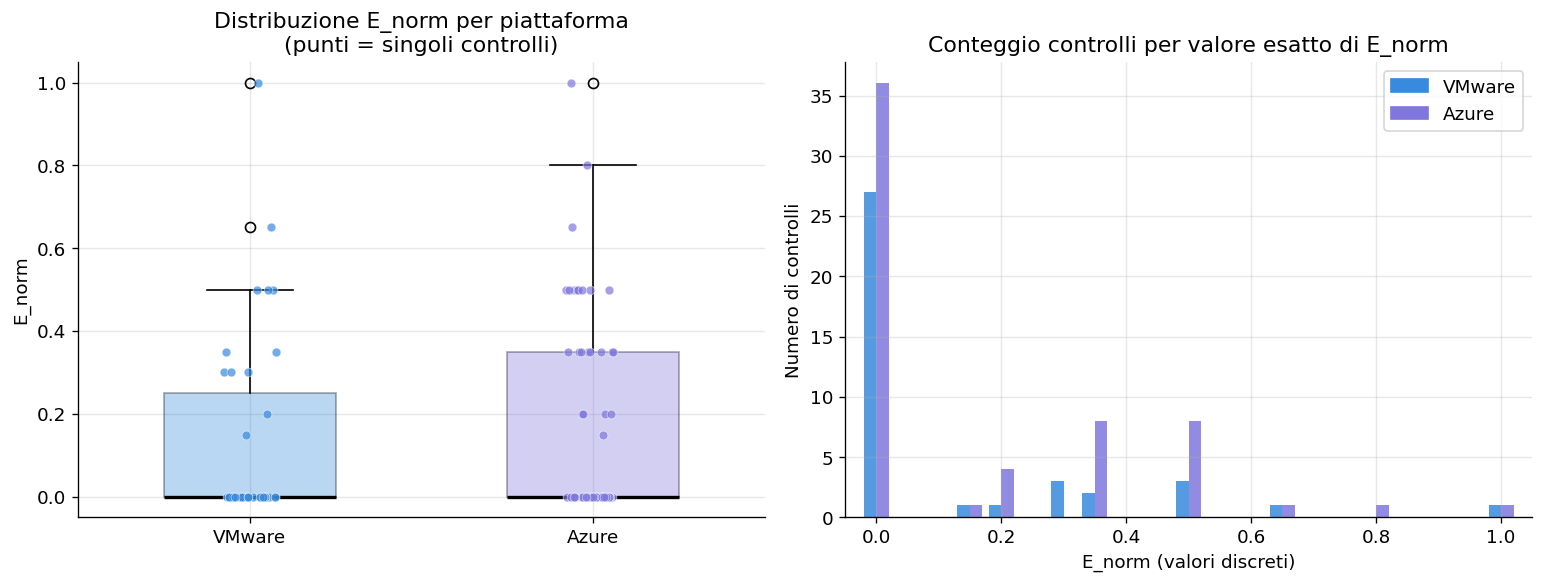

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Box plot con punti individuali sovrapposti
ax = axes[0]
bp = ax.boxplot(
    [df_vmware['E_norm'], df_azure['E_norm']],
    tick_labels=['VMware', 'Azure'],
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 2},
    widths=0.5, zorder=2,
)
for patch, color in zip(bp['boxes'], ['#378ADD', '#7F77DD']):
    patch.set_facecolor(color)
    patch.set_alpha(0.35)

rng = np.random.default_rng(42)
for i, (data, color) in enumerate(
        zip([df_vmware['E_norm'], df_azure['E_norm']], ['#378ADD', '#7F77DD']), start=1):
    jitter = rng.uniform(-0.08, 0.08, size=len(data))
    ax.scatter(np.full(len(data), i) + jitter, data, color=color, alpha=0.7,
               s=28, zorder=3, edgecolors='white', linewidth=0.4)

ax.set_ylabel('E_norm')
ax.set_title('Distribuzione E_norm per piattaforma\n(punti = singoli controlli)')

# Conteggio sui valori discreti reali di E_norm
ax2 = axes[1]
vc_v = df_vmware['E_norm'].round(4).value_counts().sort_index()
vc_a = df_azure['E_norm'].round(4).value_counts().sort_index()
all_vals = sorted(set(vc_v.index) | set(vc_a.index))
width = 0.02

for val in all_vals:
    cv, ca = vc_v.get(val, 0), vc_a.get(val, 0)
    if cv:
        ax2.bar(val - width / 2, cv, width=width, color='#378ADD', alpha=0.85)
    if ca:
        ax2.bar(val + width / 2, ca, width=width, color='#7F77DD', alpha=0.85)

ax2.set_xlabel('E_norm (valori discreti)')
ax2.set_ylabel('Numero di controlli')
ax2.set_title('Conteggio controlli per valore esatto di E_norm')
ax2.set_xlim(-0.05, 1.05)

from matplotlib.patches import Patch
ax2.legend(handles=[Patch(color='#378ADD', label='VMware'), Patch(color='#7F77DD', label='Azure')])

plt.tight_layout()
plt.savefig('confronto_piattaforme.png', dpi=300)
plt.show()